In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

In [3]:
df = pd.read_csv("AirQualityUCI.csv")

df.columns = df.columns.str.strip()

print("Dataset Shape:", df.shape)

df.head()

Dataset Shape: (9357, 13)


,datetime,CO(GT),PT08.S1(CO),C6H6(GT),PT08.S2(NMHC),NOx(GT),PT08.S3(NOx),NO2(GT),PT08.S4(NO2),PT08.S5(O3),T,RH,AH
0,2004-03-10 18:00:00,2.6,1360.0,11.9,1046.0,166.0,1056.0,113.0,1692.0,1268.0,13.6,48.9,0.7578
1,2004-03-10 19:00:00,2.0,1292.0,9.4,955.0,103.0,1174.0,92.0,1559.0,972.0,13.3,47.7,0.7255
2,2004-03-10 20:00:00,2.2,1402.0,9.0,939.0,131.0,1140.0,114.0,1555.0,1074.0,11.9,54.0,0.7502
3,2004-03-10 21:00:00,2.2,1376.0,9.2,948.0,172.0,1092.0,122.0,1584.0,1203.0,11.0,60.0,0.7867
4,2004-03-10 22:00:00,1.6,1272.0,6.5,836.0,131.0,1205.0,116.0,1490.0,1110.0,11.2,59.6,0.7888


In [4]:
pollutants = [
    'CO(GT)',
    'C6H6(GT)',
    'NOx(GT)',
    'NO2(GT)']

print(df[pollutants].describe())

            CO(GT)     C6H6(GT)      NOx(GT)      NO2(GT)
count  9357.000000  9357.000000  9357.000000  9357.000000
mean      2.130603    10.179155   241.922197   109.632094
std       1.431736     7.503812   204.315075    46.462311
min       0.100000     0.100000     2.000000     2.000000
25%       1.100000     4.500000    96.000000    76.000000
50%       1.800000     8.300000   180.000000   104.917526
75%       2.900000    14.100000   326.000000   136.314685
max      11.900000    63.700000  1479.000000   340.000000


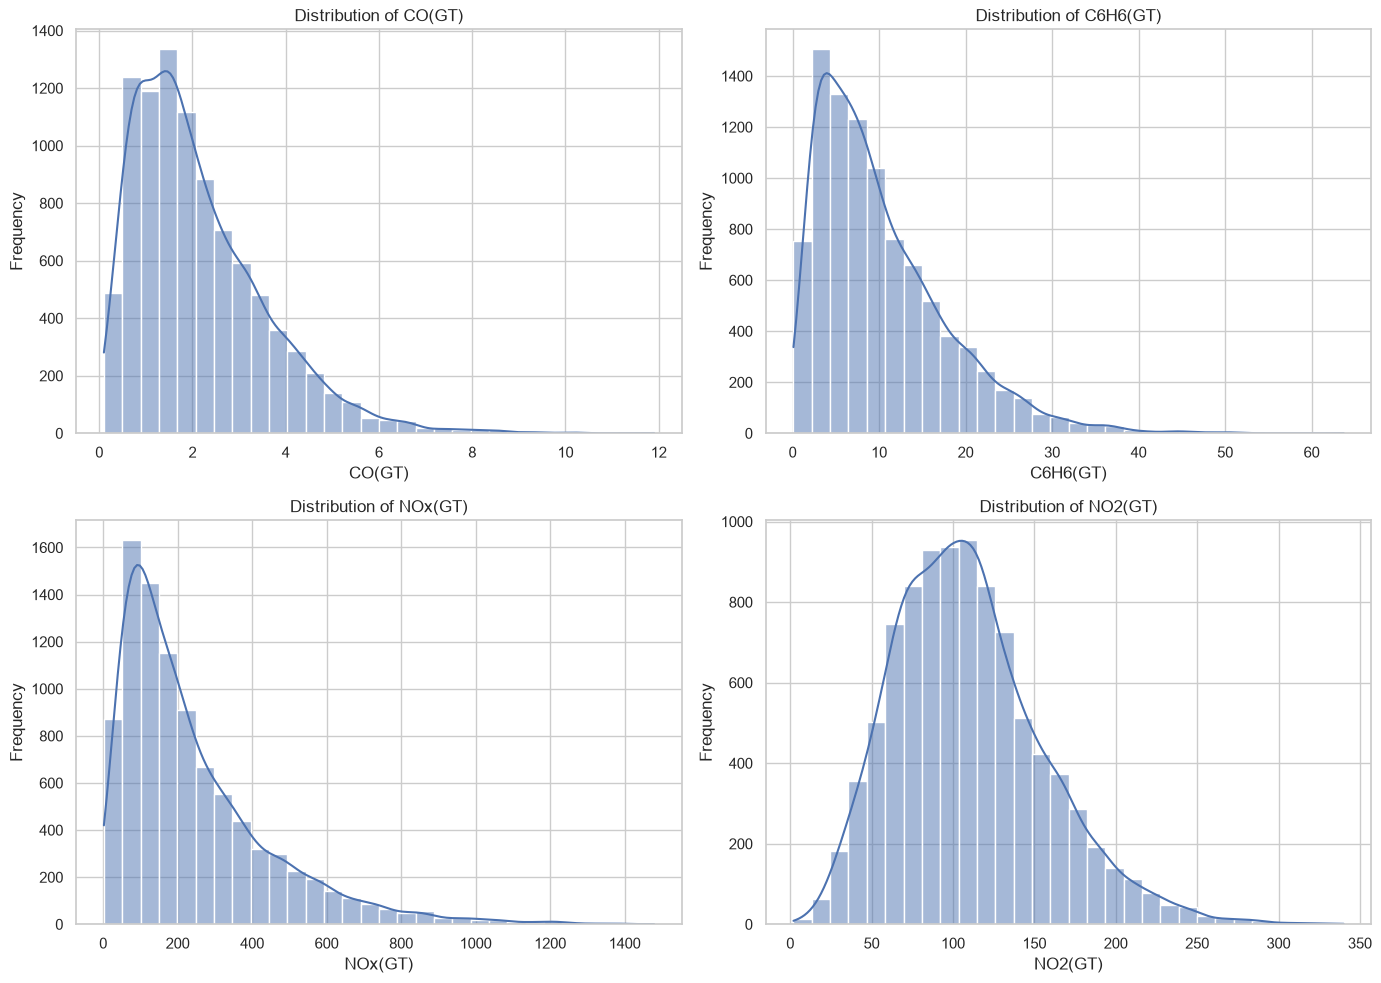

In [5]:
plt.figure(figsize=(14, 10))

for i, col in enumerate(pollutants):

    plt.subplot(2, 2, i + 1)

    sns.histplot(
        df[col].dropna(),
        kde=True,
        bins=30
    )

    plt.title(f"Distribution of {col}")
    plt.xlabel(col)
    plt.ylabel("Frequency")

plt.tight_layout()
plt.show()

In [7]:
df['datetime'] = pd.to_datetime(df['datetime'], errors='coerce')

In [23]:
# Extract hour from datetime column
df['Hour'] = df['datetime'].dt.hour

# Calculate average pollutant concentration for each hour
hourly_pollution = df.groupby('Hour')[pollutants].mean()

print(hourly_pollution)

        CO(GT)   C6H6(GT)     NOx(GT)     NO2(GT)
Hour                                             
0     1.846334   7.849924  198.104375  102.755965
1     1.567172   6.235825  169.406229   91.701694
2     1.262307   4.705032  136.469005   78.751202
3     1.079787   3.749138  120.142474   71.485986
4     0.991097   3.313700  104.496713   64.505385
5     0.946595   3.467815  109.477634   65.380538
6     1.122774   5.101730  142.674707   75.786878
7     1.857740  10.549490  227.510308   95.486228
8     2.729271  15.854943  330.172404  118.443270
9     2.853542  14.653473  346.421782  127.082363
10    2.511499  12.260258  326.642424  128.944093
11    2.251697  11.084479  299.646125  126.181019
12    2.176861  10.883315  269.781099  120.819553
13    2.210791  11.029330  253.212042  116.463826
14    2.146237  10.400536  243.552771  113.906324
15    2.087831  10.334652  239.915719  114.585965
16    2.260967  11.142854  258.370960  120.075452
17    2.717517  13.827428  298.849663  130.821214


In [15]:
# Extract hour from datetime column
df['Hour'] = df['datetime'].dt.hour

# Calculate average pollutant concentration for each hour
hourly_pollution = df.groupby('Hour')[pollutants].mean()

print(hourly_pollution)


        CO(GT)   C6H6(GT)     NOx(GT)     NO2(GT)
Hour                                             
0     1.846334   7.849924  198.104375  102.755965
1     1.567172   6.235825  169.406229   91.701694
2     1.262307   4.705032  136.469005   78.751202
3     1.079787   3.749138  120.142474   71.485986
4     0.991097   3.313700  104.496713   64.505385
5     0.946595   3.467815  109.477634   65.380538
6     1.122774   5.101730  142.674707   75.786878
7     1.857740  10.549490  227.510308   95.486228
8     2.729271  15.854943  330.172404  118.443270
9     2.853542  14.653473  346.421782  127.082363
10    2.511499  12.260258  326.642424  128.944093
11    2.251697  11.084479  299.646125  126.181019
12    2.176861  10.883315  269.781099  120.819553
13    2.210791  11.029330  253.212042  116.463826
14    2.146237  10.400536  243.552771  113.906324
15    2.087831  10.334652  239.915719  114.585965
16    2.260967  11.142854  258.370960  120.075452
17    2.717517  13.827428  298.849663  130.821214


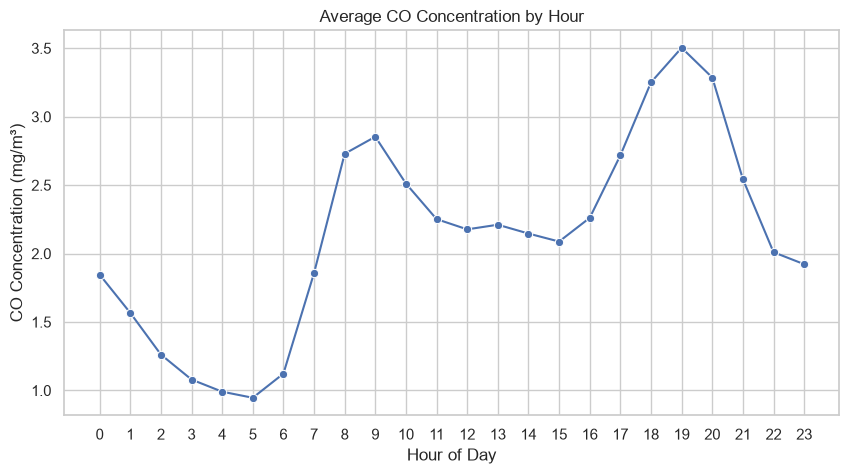

In [24]:
plt.figure(figsize=(10, 5))

sns.lineplot(
    x=hourly_pollution.index,
    y=hourly_pollution['CO(GT)'],
    marker='o'
)

plt.title('Average CO Concentration by Hour')
plt.xlabel('Hour of Day')
plt.ylabel('CO Concentration (mg/m³)')
plt.xticks(range(0, 24))
plt.show()

             CO(GT)   C6H6(GT)     NOx(GT)     NO2(GT)
Day                                                   
Monday     2.068241   9.942110  236.476382  107.877282
Tuesday    2.300498  11.709921  261.959265  112.943683
Wednesday  2.277207  11.896058  260.181448  115.575911
Thursday   2.309944  11.578250  265.781746  115.291874
Friday     2.462439  11.635596  271.393158  118.392644
Saturday   1.912591   8.489910  223.681095  104.974539
Sunday     1.587878   6.050979  174.548168   92.495711


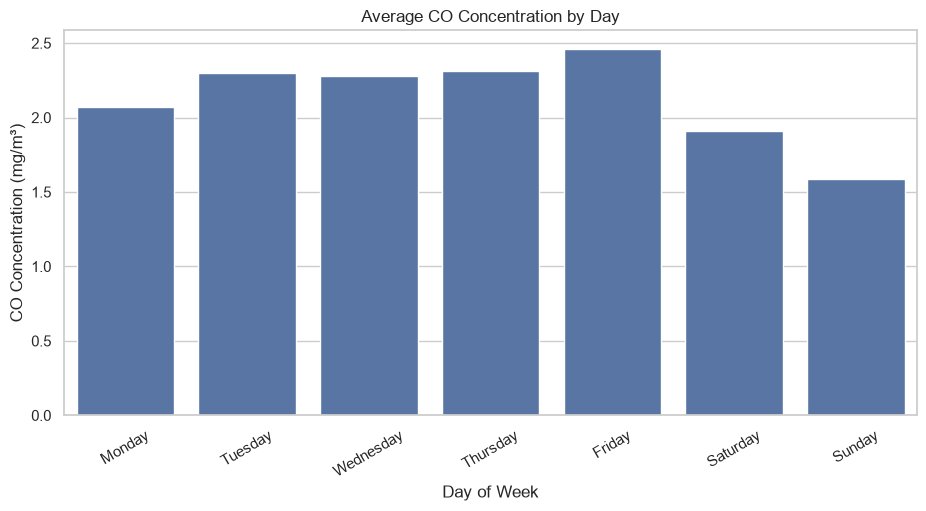

In [25]:

df['Day'] = df['datetime'].dt.day_name()
day_order = [
    'Monday', 'Tuesday', 'Wednesday',
    'Thursday', 'Friday', 'Saturday', 'Sunday'
]



daily_pollution = df.groupby('Day')[pollutants].mean()

daily_pollution = daily_pollution.reindex(day_order)

print(daily_pollution)

plt.figure(figsize=(11, 5))

sns.barplot(
    x=daily_pollution.index,
    y=daily_pollution['CO(GT)']
)

plt.title('Average CO Concentration by Day')
plt.xlabel('Day of Week')
plt.ylabel('CO Concentration (mg/m³)')
plt.xticks(rotation=30)
plt.show()

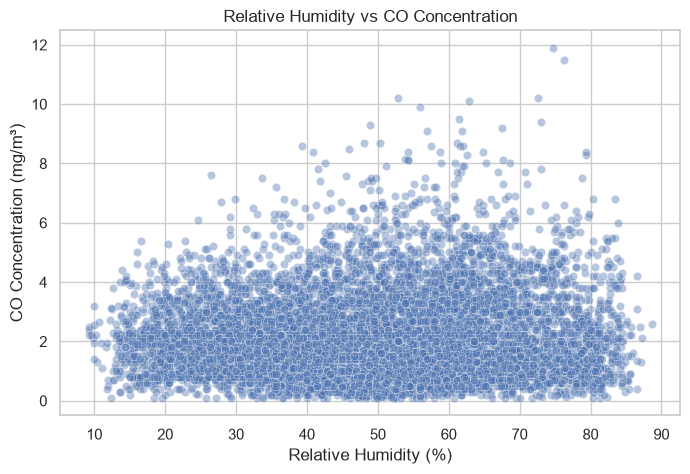

In [26]:
plt.figure(figsize=(8, 5))

sns.scatterplot(
    data=df,
    x='RH',
    y='CO(GT)',
    alpha=0.4
)

plt.title('Relative Humidity vs CO Concentration')
plt.xlabel('Relative Humidity (%)')
plt.ylabel('CO Concentration (mg/m³)')
plt.show()

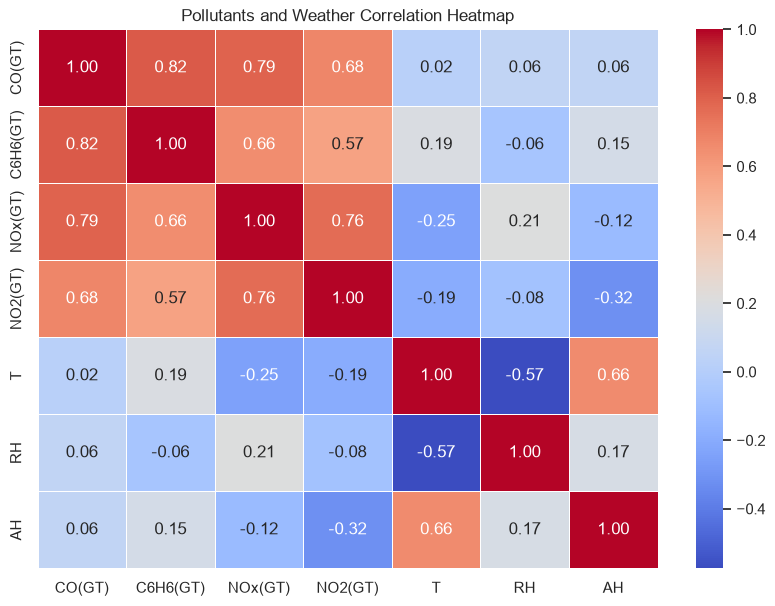

In [27]:
correlation = df[
    pollutants + ['T', 'RH', 'AH']
].corr()

plt.figure(figsize=(10, 7))

sns.heatmap(
    correlation,
    annot=True,
    cmap='coolwarm',
    fmt='.2f',
    linewidths=0.5
)

plt.title('Pollutants and Weather Correlation Heatmap')
plt.show()

In [28]:
print(df.columns.tolist())
print(df['datetime'].dtype)

['datetime', 'CO(GT)', 'PT08.S1(CO)', 'C6H6(GT)', 'PT08.S2(NMHC)', 'NOx(GT)', 'PT08.S3(NOx)', 'NO2(GT)', 'PT08.S4(NO2)', 'PT08.S5(O3)', 'T', 'RH', 'AH', 'Hour', 'Day']
datetime64[us]


In [30]:
print(pollutants)

['CO(GT)', 'C6H6(GT)', 'NOx(GT)', 'NO2(GT)']


In [33]:
# Hourly Pollution Analysis

df['Hour'] = df['datetime'].dt.hour

hourly_pollution = df.groupby('Hour')[pollutants].mean()

display(hourly_pollution)

,CO(GT),C6H6(GT),NOx(GT),NO2(GT)
Hour,,,,
0,1.846334,7.849924,198.104375,102.755965
1,1.567172,6.235825,169.406229,91.701694
2,1.262307,4.705032,136.469005,78.751202
3,1.079787,3.749138,120.142474,71.485986
4,0.991097,3.313700,104.496713,64.505385
5,0.946595,3.467815,109.477634,65.380538
6,1.122774,5.101730,142.674707,75.786878
7,1.857740,10.549490,227.510308,95.486228
8,2.729271,15.854943,330.172404,118.443270


In [35]:
# Check datetime column
print(df['datetime'].dtype)

# Extract hour
hour_values = pd.to_datetime(df['datetime']).dt.hour

# Store hour in dataframe
df['Hour'] = hour_values

# Display results
print(df[['datetime', 'Hour']].head())

datetime64[us]
             datetime  Hour
0 2004-03-10 18:00:00    18
1 2004-03-10 19:00:00    19
2 2004-03-10 20:00:00    20
3 2004-03-10 21:00:00    21
4 2004-03-10 22:00:00    22


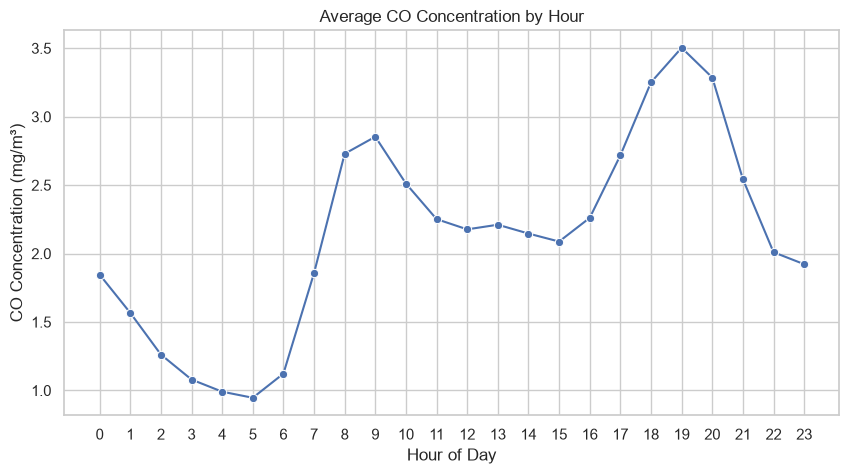

In [37]:
plt.figure(figsize=(10, 5))

sns.lineplot(
    x=hourly_pollution.index,
    y=hourly_pollution['CO(GT)'],
    marker='o'
)

plt.title('Average CO Concentration by Hour')
plt.xlabel('Hour of Day')
plt.ylabel('CO Concentration (mg/m³)')

plt.xticks(range(0, 24))
plt.grid(True)

plt.show()

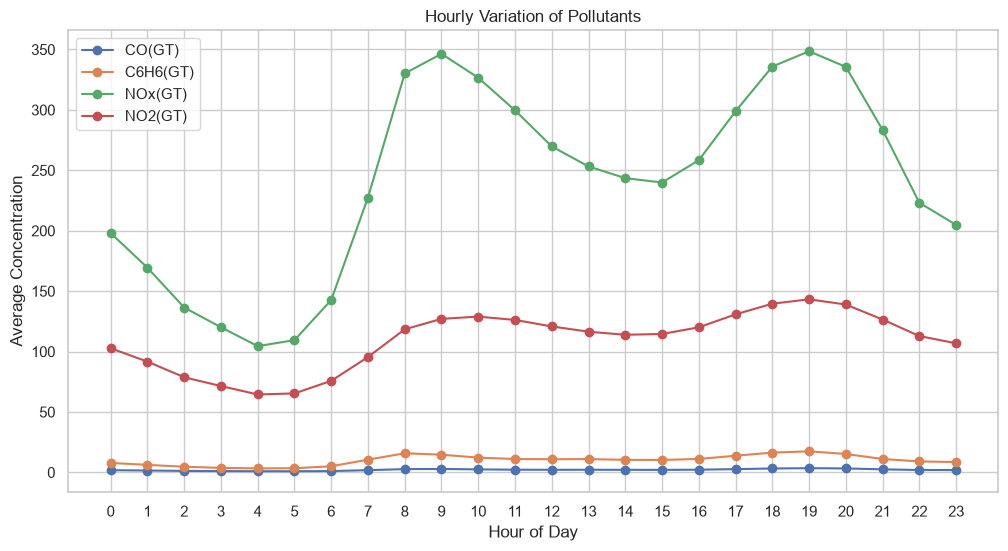

In [38]:
hourly_pollution.plot(
    figsize=(12, 6),
    marker='o'
)

plt.title('Hourly Variation of Pollutants')
plt.xlabel('Hour of Day')
plt.ylabel('Average Concentration')
plt.xticks(range(0, 24))
plt.grid(True)
plt.legend()
plt.show()

In [40]:
print(df.columns.tolist())
print(type(df.index))
print(df.head())

['datetime', 'CO(GT)', 'PT08.S1(CO)', 'C6H6(GT)', 'PT08.S2(NMHC)', 'NOx(GT)', 'PT08.S3(NOx)', 'NO2(GT)', 'PT08.S4(NO2)', 'PT08.S5(O3)', 'T', 'RH', 'AH', 'Hour', 'Day']
<class 'pandas.RangeIndex'>
             datetime  CO(GT)  PT08.S1(CO)  C6H6(GT)  PT08.S2(NMHC)  NOx(GT)  \
0 2004-03-10 18:00:00     2.6       1360.0      11.9         1046.0    166.0   
1 2004-03-10 19:00:00     2.0       1292.0       9.4          955.0    103.0   
2 2004-03-10 20:00:00     2.2       1402.0       9.0          939.0    131.0   
3 2004-03-10 21:00:00     2.2       1376.0       9.2          948.0    172.0   
4 2004-03-10 22:00:00     1.6       1272.0       6.5          836.0    131.0   

   PT08.S3(NOx)  NO2(GT)  PT08.S4(NO2)  PT08.S5(O3)     T    RH      AH  Hour  \
0        1056.0    113.0        1692.0       1268.0  13.6  48.9  0.7578    18   
1        1174.0     92.0        1559.0        972.0  13.3  47.7  0.7255    19   
2        1140.0    114.0        1555.0       1074.0  11.9  54.0  0.7502    20   

In [44]:
df['DayOfWeek'] = pd.to_datetime(df['datetime']).dt.day_name()

In [45]:
# Check whether index is datetime format
if isinstance(df.index, pd.DatetimeIndex):

    df['DayOfWeek'] = df.index.day_name()

else:
    print("Index is not in datetime format.")

Index is not in datetime format.


In [46]:
print(df[['DayOfWeek']].head())

   DayOfWeek
0  Wednesday
1  Wednesday
2  Wednesday
3  Wednesday
4  Wednesday


In [49]:
print("COLUMN NAMES:")
print(df.columns.tolist())

print("\nINDEX TYPE:")
print(type(df.index))

print("\nINDEX NAME:")
print(df.index.name)

print("\nFIRST 5 ROWS:")
print(df.head())

COLUMN NAMES:
['datetime', 'CO(GT)', 'PT08.S1(CO)', 'C6H6(GT)', 'PT08.S2(NMHC)', 'NOx(GT)', 'PT08.S3(NOx)', 'NO2(GT)', 'PT08.S4(NO2)', 'PT08.S5(O3)', 'T', 'RH', 'AH', 'Hour', 'Day', 'DayOfWeek']

INDEX TYPE:
<class 'pandas.RangeIndex'>

INDEX NAME:
None

FIRST 5 ROWS:
             datetime  CO(GT)  PT08.S1(CO)  C6H6(GT)  PT08.S2(NMHC)  NOx(GT)  \
0 2004-03-10 18:00:00     2.6       1360.0      11.9         1046.0    166.0   
1 2004-03-10 19:00:00     2.0       1292.0       9.4          955.0    103.0   
2 2004-03-10 20:00:00     2.2       1402.0       9.0          939.0    131.0   
3 2004-03-10 21:00:00     2.2       1376.0       9.2          948.0    172.0   
4 2004-03-10 22:00:00     1.6       1272.0       6.5          836.0    131.0   

   PT08.S3(NOx)  NO2(GT)  PT08.S4(NO2)  PT08.S5(O3)     T    RH      AH  Hour  \
0        1056.0    113.0        1692.0       1268.0  13.6  48.9  0.7578    18   
1        1174.0     92.0        1559.0        972.0  13.3  47.7  0.7255    19   
2      

In [51]:
print(df.columns.tolist())

['datetime', 'CO(GT)', 'PT08.S1(CO)', 'C6H6(GT)', 'PT08.S2(NMHC)', 'NOx(GT)', 'PT08.S3(NOx)', 'NO2(GT)', 'PT08.S4(NO2)', 'PT08.S5(O3)', 'T', 'RH', 'AH', 'Hour', 'Day', 'DayOfWeek']


In [53]:
print(df[['datetime', 'DayOfWeek']].head())

             datetime  DayOfWeek
0 2004-03-10 18:00:00  Wednesday
1 2004-03-10 19:00:00  Wednesday
2 2004-03-10 20:00:00  Wednesday
3 2004-03-10 21:00:00  Wednesday
4 2004-03-10 22:00:00  Wednesday


In [54]:
import numpy as np
import matplotlib.pyplot as plt

pollutants = ['CO(GT)', 'NOx(GT)', 'NO2(GT)']

# Replace invalid values
df[pollutants] = df[pollutants].replace(-200, np.nan)

# Calculate average pollution by weekday
daily_pollution = df.groupby('DayOfWeek')[pollutants].mean()

# Arrange weekdays in order
days = ['Monday', 'Tuesday', 'Wednesday',
        'Thursday', 'Friday', 'Saturday', 'Sunday']

daily_pollution = daily_pollution.reindex(days)

print(daily_pollution)

             CO(GT)     NOx(GT)     NO2(GT)
DayOfWeek                                  
Monday     2.068241  236.476382  107.877282
Tuesday    2.300498  261.959265  112.943683
Wednesday  2.277207  260.181448  115.575911
Thursday   2.309944  265.781746  115.291874
Friday     2.462439  271.393158  118.392644
Saturday   1.912591  223.681095  104.974539
Sunday     1.587878  174.548168   92.495711


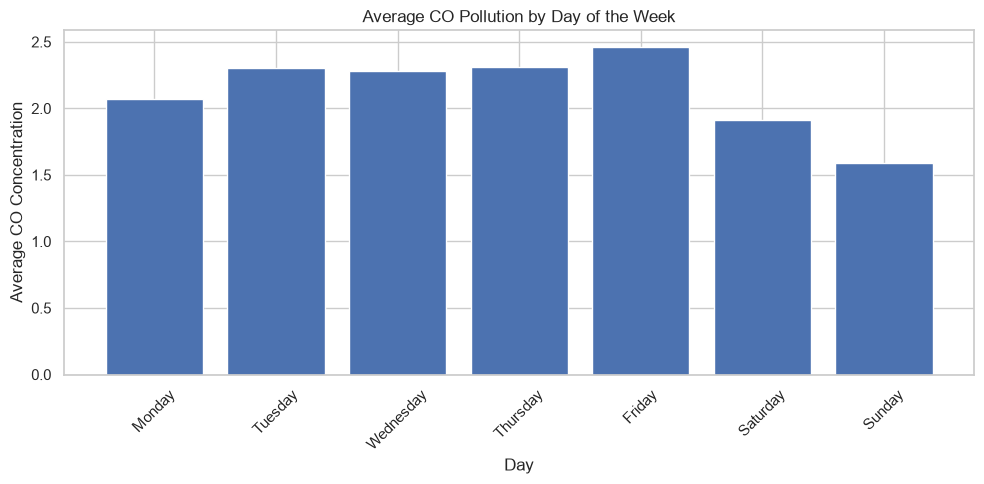

In [55]:
plt.figure(figsize=(10, 5))
plt.bar(daily_pollution.index, daily_pollution['CO(GT)'])

plt.title('Average CO Pollution by Day of the Week')
plt.xlabel('Day')
plt.ylabel('Average CO Concentration')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

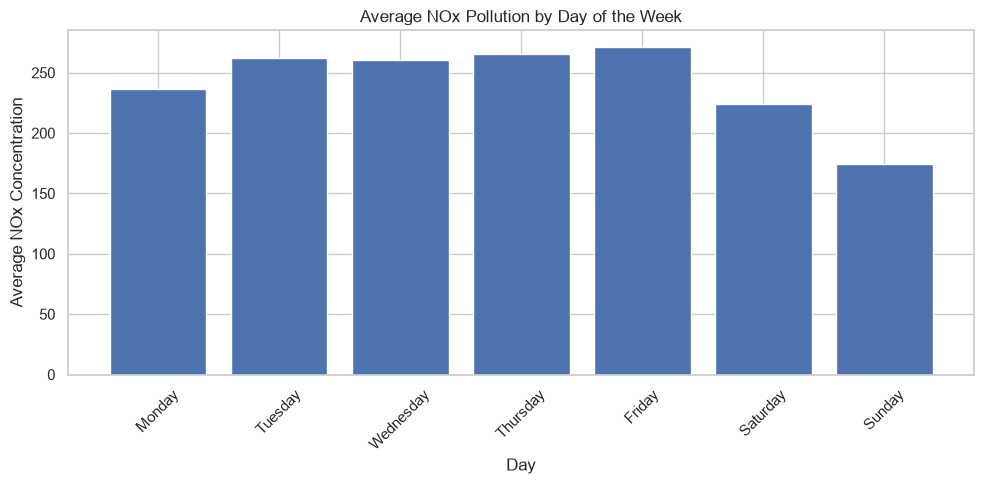

In [56]:
plt.figure(figsize=(10, 5))
plt.bar(daily_pollution.index, daily_pollution['NOx(GT)'])

plt.title('Average NOx Pollution by Day of the Week')
plt.xlabel('Day')
plt.ylabel('Average NOx Concentration')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

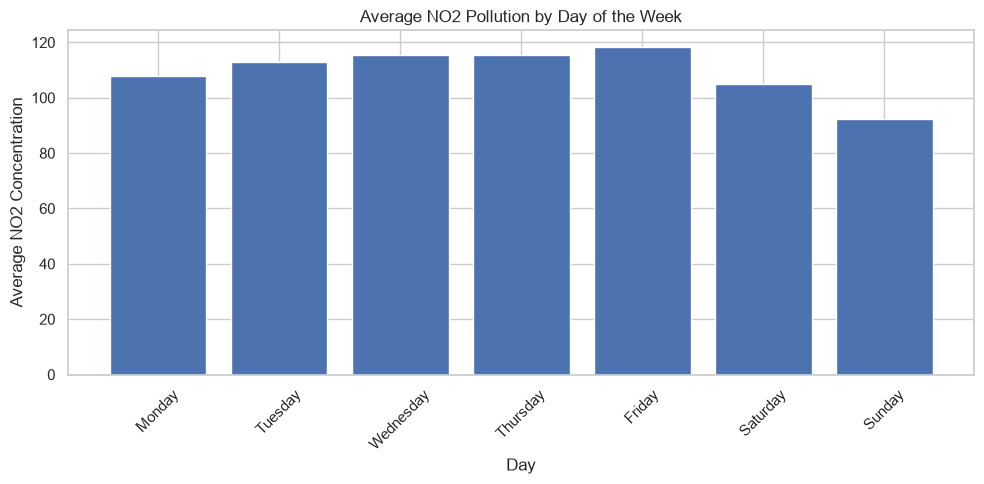

In [57]:
plt.figure(figsize=(10, 5))
plt.bar(daily_pollution.index, daily_pollution['NO2(GT)'])

plt.title('Average NO2 Pollution by Day of the Week')
plt.xlabel('Day')
plt.ylabel('Average NO2 Concentration')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [58]:
for pollutant in pollutants:

    highest_day = daily_pollution[pollutant].idxmax()
    lowest_day = daily_pollution[pollutant].idxmin()

    print(f"\nPollutant: {pollutant}")
    print(f"Highest: {highest_day}")
    print(f"Lowest: {lowest_day}")


Pollutant: CO(GT)
Highest: Friday
Lowest: Sunday

Pollutant: NOx(GT)
Highest: Friday
Lowest: Sunday

Pollutant: NO2(GT)
Highest: Friday
Lowest: Sunday


In [60]:
# Ensure datetime is in datetime format
df['datetime'] = pd.to_datetime(df['datetime'], errors='coerce')

# Extract month
df['Month'] = df['datetime'].dt.month

# Display results
print(df[['datetime', 'Month']].head())

             datetime  Month
0 2004-03-10 18:00:00      3
1 2004-03-10 19:00:00      3
2 2004-03-10 20:00:00      3
3 2004-03-10 21:00:00      3
4 2004-03-10 22:00:00      3


In [61]:
# Identify weekends
df['IsWeekend'] = df['datetime'].dt.dayofweek >= 5

# Display results
print(df[['DayOfWeek', 'IsWeekend']].head(10))

   DayOfWeek  IsWeekend
0  Wednesday      False
1  Wednesday      False
2  Wednesday      False
3  Wednesday      False
4  Wednesday      False
5  Wednesday      False
6   Thursday      False
7   Thursday      False
8   Thursday      False
9   Thursday      False


In [62]:
# Convert hour into cyclical features
df['Hour_sin'] = np.sin(2 * np.pi * df['Hour'] / 24)

df['Hour_cos'] = np.cos(2 * np.pi * df['Hour'] / 24)

# Convert weekday into cyclical features
df['DayOfWeek_num'] = df['datetime'].dt.dayofweek

df['Day_sin'] = np.sin(2 * np.pi * df['DayOfWeek_num'] / 7)

df['Day_cos'] = np.cos(2 * np.pi * df['DayOfWeek_num'] / 7)

print(df[['Hour', 'Hour_sin', 'Hour_cos',
          'DayOfWeek_num', 'Day_sin', 'Day_cos']].head())

   Hour  Hour_sin      Hour_cos  DayOfWeek_num   Day_sin   Day_cos
0    18 -1.000000 -1.836970e-16              2  0.974928 -0.222521
1    19 -0.965926  2.588190e-01              2  0.974928 -0.222521
2    20 -0.866025  5.000000e-01              2  0.974928 -0.222521
3    21 -0.707107  7.071068e-01              2  0.974928 -0.222521
4    22 -0.500000  8.660254e-01              2  0.974928 -0.222521


In [63]:
# Identify numerical columns
numeric_columns = df.select_dtypes(include=np.number).columns

# Replace -200 with NaN
df[numeric_columns] = df[numeric_columns].replace(-200, np.nan)

# Check missing values
print(df.isnull().sum())

datetime         0
CO(GT)           0
PT08.S1(CO)      0
C6H6(GT)         0
PT08.S2(NMHC)    0
NOx(GT)          0
PT08.S3(NOx)     0
NO2(GT)          0
PT08.S4(NO2)     0
PT08.S5(O3)      0
T                0
RH               0
AH               0
Hour             0
Day              0
DayOfWeek        0
Month            0
IsWeekend        0
Hour_sin         0
Hour_cos         0
DayOfWeek_num    0
Day_sin          0
Day_cos          0
dtype: int64


In [64]:
# Select input features
features = [
    'Hour',
    'Day',
    'Month',
    'IsWeekend',
    'Hour_sin',
    'Hour_cos',
    'Day_sin',
    'Day_cos',
    'T',
    'RH',
    'AH',
    'PT08.S1(CO)',
    'PT08.S2(NMHC)',
    'PT08.S3(NOx)',
    'PT08.S4(NO2)',
    'PT08.S5(O3)'
]

# Select target
target = 'CO(GT)'

# Create final modeling DataFrame
model_df = df[features + [target]].copy()

# Remove rows where target is missing
model_df = model_df.dropna(subset=[target])

# Display dataset
print("Dataset shape:", model_df.shape)

print("\nFirst five records:")
print(model_df.head())

Dataset shape: (9357, 17)

First five records:
   Hour        Day  Month  IsWeekend  Hour_sin      Hour_cos   Day_sin  \
0    18  Wednesday      3      False -1.000000 -1.836970e-16  0.974928   
1    19  Wednesday      3      False -0.965926  2.588190e-01  0.974928   
2    20  Wednesday      3      False -0.866025  5.000000e-01  0.974928   
3    21  Wednesday      3      False -0.707107  7.071068e-01  0.974928   
4    22  Wednesday      3      False -0.500000  8.660254e-01  0.974928   

    Day_cos     T    RH      AH  PT08.S1(CO)  PT08.S2(NMHC)  PT08.S3(NOx)  \
0 -0.222521  13.6  48.9  0.7578       1360.0         1046.0        1056.0   
1 -0.222521  13.3  47.7  0.7255       1292.0          955.0        1174.0   
2 -0.222521  11.9  54.0  0.7502       1402.0          939.0        1140.0   
3 -0.222521  11.0  60.0  0.7867       1376.0          948.0        1092.0   
4 -0.222521  11.2  59.6  0.7888       1272.0          836.0        1205.0   

   PT08.S4(NO2)  PT08.S5(O3)  CO(GT)  
0     

In [65]:
# Calculate correlation
correlation = model_df.corr(numeric_only=True)

# Display correlation with CO
print(correlation['CO(GT)'].sort_values(ascending=False))

CO(GT)           1.000000
PT08.S2(NMHC)    0.807094
PT08.S1(CO)      0.794054
PT08.S5(O3)      0.774817
PT08.S4(NO2)     0.556564
Hour             0.321052
Month            0.143575
Day_sin          0.119574
RH               0.062650
AH               0.060264
T                0.018899
Day_cos         -0.104999
Hour_cos        -0.156057
IsWeekend       -0.168674
Hour_sin        -0.320123
PT08.S3(NOx)    -0.647713
Name: CO(GT), dtype: float64


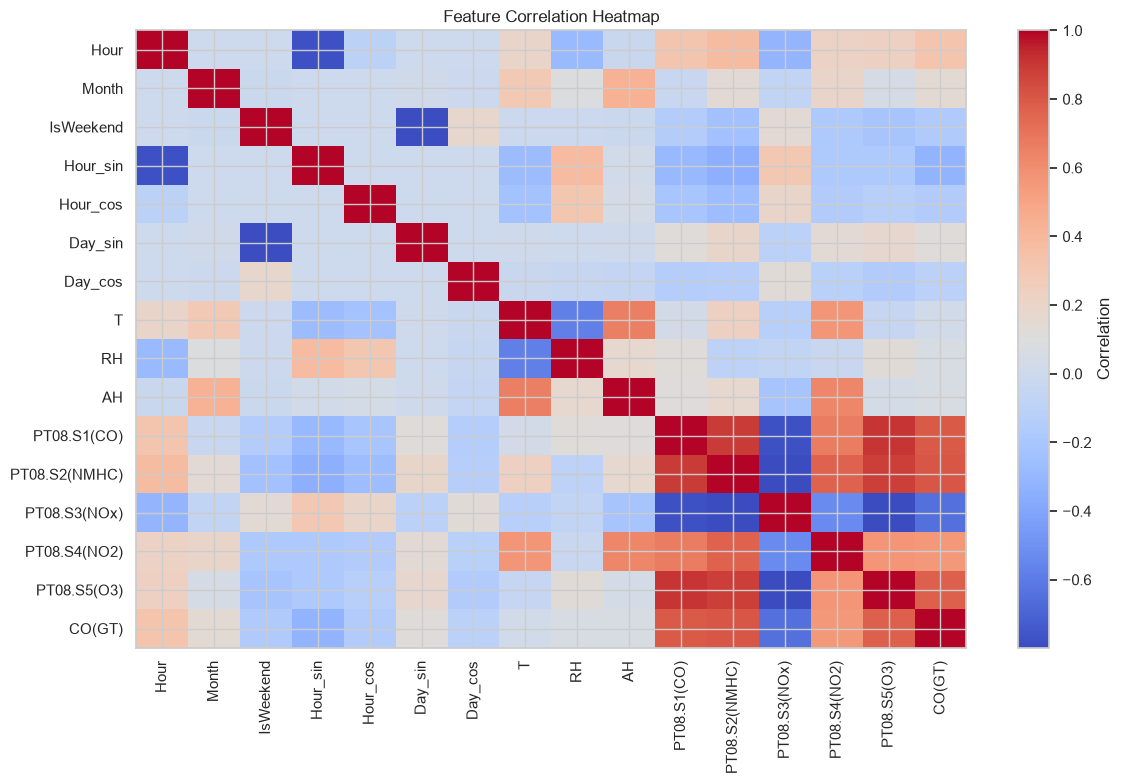

In [66]:
plt.figure(figsize=(12, 8))

plt.imshow(correlation, cmap='coolwarm', aspect='auto')

plt.colorbar(label='Correlation')

plt.xticks(
    range(len(correlation.columns)),
    correlation.columns,
    rotation=90
)

plt.yticks(
    range(len(correlation.columns)),
    correlation.columns
)

plt.title('Feature Correlation Heatmap')

plt.tight_layout()
plt.show()

In [67]:
print("STEP 5 - FINAL DATASET SUMMARY")

print("\nTotal records:", model_df.shape[0])

print("Total features:", len(features))

print("Target variable:", target)

print("\nMissing values:")
print(model_df.isnull().sum())

print("\nDataset information:")
model_df.info()

STEP 5 - FINAL DATASET SUMMARY

Total records: 9357
Total features: 16
Target variable: CO(GT)

Missing values:
Hour             0
Day              0
Month            0
IsWeekend        0
Hour_sin         0
Hour_cos         0
Day_sin          0
Day_cos          0
T                0
RH               0
AH               0
PT08.S1(CO)      0
PT08.S2(NMHC)    0
PT08.S3(NOx)     0
PT08.S4(NO2)     0
PT08.S5(O3)      0
CO(GT)           0
dtype: int64

Dataset information:
<class 'pandas.DataFrame'>
RangeIndex: 9357 entries, 0 to 9356
Data columns (total 17 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Hour           9357 non-null   int32  
 1   Day            9357 non-null   str    
 2   Month          9357 non-null   int32  
 3   IsWeekend      9357 non-null   bool   
 4   Hour_sin       9357 non-null   float64
 5   Hour_cos       9357 non-null   float64
 6   Day_sin        9357 non-null   float64
 7   Day_cos        9357 non-null   fl

In [68]:
# Import required libraries
import pandas as pd
import numpy as np

# Select target and features
target = 'CO(GT)'

features = [
    'Hour',
    'Day',
    'Month',
    'IsWeekend',
    'Hour_sin',
    'Hour_cos',
    'Day_sin',
    'Day_cos',
    'T',
    'RH',
    'AH',
    'PT08.S1(CO)',
    'PT08.S2(NMHC)',
    'PT08.S3(NOx)',
    'PT08.S4(NO2)',
    'PT08.S5(O3)'
]

# Prepare modeling dataset
data = df[['datetime'] + features + [target]].copy()

# Sort observations chronologically
data = data.sort_values('datetime')

# Remove records with missing target
data = data.dropna(subset=[target])

# Separate X and y
X = data[features]
y = data[target]

# Split dataset chronologically
split = int(len(data) * 0.80)

X_train = X.iloc[:split]
X_test = X.iloc[split:]

y_train = y.iloc[:split]
y_test = y.iloc[split:]

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

print("Training target:", y_train.shape)
print("Testing target:", y_test.shape)

Training data: (7485, 16)
Testing data: (1872, 16)
Training target: (7485,)
Testing target: (1872,)


In [69]:
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression

# Create preprocessing and model pipeline
model = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler()),
    ('regressor', LinearRegression())
])

print("Pipeline created successfully!")

Pipeline created successfully!


In [71]:
print("Non-numeric columns in X_train:")

print(X_train.select_dtypes(exclude=np.number).columns.tolist())

print("\nData types:")
print(X_train.dtypes)

Non-numeric columns in X_train:
['Day', 'IsWeekend']

Data types:
Hour               int32
Day                  str
Month              int32
IsWeekend           bool
Hour_sin         float64
Hour_cos         float64
Day_sin          float64
Day_cos          float64
T                float64
RH               float64
AH               float64
PT08.S1(CO)      float64
PT08.S2(NMHC)    float64
PT08.S3(NOx)     float64
PT08.S4(NO2)     float64
PT08.S5(O3)      float64
dtype: object


In [74]:
# Recreate numerical features
features = [
    'Hour',
    'Day',
    'Month',
    'IsWeekend',
    'Hour_sin',
    'Hour_cos',
    'Day_sin',
    'Day_cos',
    'T',
    'RH',
    'AH',
    'PT08.S1(CO)',
    'PT08.S2(NMHC)',
    'PT08.S3(NOx)',
    'PT08.S4(NO2)',
    'PT08.S5(O3)'
]

# Create modeling dataset
data = df[['datetime'] + features + ['CO(GT)']].copy()

# Sort by datetime
data = data.sort_values('datetime')

# Remove missing target values
data = data.dropna(subset=['CO(GT)'])

# Remove the text-based Day column
features = [
    'Hour', 'Month', 'IsWeekend',
    'Hour_sin', 'Hour_cos',
    'Day_sin', 'Day_cos',
    'T', 'RH', 'AH',
    'PT08.S1(CO)', 'PT08.S2(NMHC)',
    'PT08.S3(NOx)', 'PT08.S4(NO2)', 'PT08.S5(O3)'
]

# Create fresh X and y
X = model_df[features].copy()
y = model_df['CO(GT)'].copy()

# Convert Boolean values into integers
X['IsWeekend'] = X['IsWeekend'].astype(int)

print(X.dtypes)

# Separate input and output
X = data[features]
y = data['CO(GT)']

# Convert Boolean features to integers
X['IsWeekend'] = X['IsWeekend'].astype(int)

# Split chronologically (80:20)
split = int(len(data) * 0.80)

X_train = X.iloc[:split].copy()
X_test = X.iloc[split:].copy()

y_train = y.iloc[:split]
y_test = y.iloc[split:]

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

Hour               int32
Month              int32
IsWeekend          int64
Hour_sin         float64
Hour_cos         float64
Day_sin          float64
Day_cos          float64
T                float64
RH               float64
AH               float64
PT08.S1(CO)      float64
PT08.S2(NMHC)    float64
PT08.S3(NOx)     float64
PT08.S4(NO2)     float64
PT08.S5(O3)      float64
dtype: object
Training data: (7485, 15)
Testing data: (1872, 15)


In [75]:
model.fit(X_train, y_train)

print("Linear Regression Model Training Completed!")

Linear Regression Model Training Completed!


In [76]:
# Train the model
model.fit(X_train, y_train)

print("Linear Regression Model Training Completed!")

Linear Regression Model Training Completed!


In [77]:
# Predict CO concentration
y_pred = model.predict(X_test)

# Display actual and predicted values
results = pd.DataFrame({
    'Actual CO': y_test.values,
    'Predicted CO': y_pred
})

print(results.head(10))

   Actual CO  Predicted CO
0        0.7      0.464716
1        1.1      0.731052
2        1.1      0.878219
3        1.2      0.991349
4        2.0      1.627336
5        2.2      1.628152
6        1.5      1.031068
7        1.2      0.894321
8        1.5      1.091419
9        1.4      0.954419


In [78]:
from sklearn.metrics import mean_absolute_error
from sklearn.metrics import mean_squared_error
from sklearn.metrics import r2_score

# Calculate evaluation metrics
mae = mean_absolute_error(y_test, y_pred)

mse = mean_squared_error(y_test, y_pred)

rmse = np.sqrt(mse)

r2 = r2_score(y_test, y_pred)

# Display results
print("MODEL PERFORMANCE")

print("MAE:", mae)

print("MSE:", mse)

print("RMSE:", rmse)

print("R2 Score:", r2)

MODEL PERFORMANCE
MAE: 0.4985956004697545
MSE: 0.49840638395831915
RMSE: 0.7059790251546565
R2 Score: 0.7386990913850001


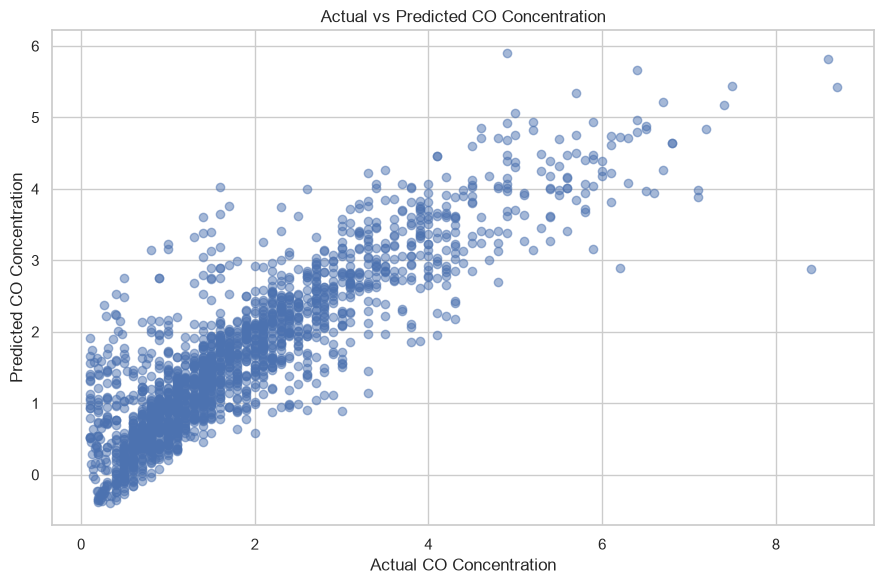

In [79]:
plt.figure(figsize=(9, 6))

plt.scatter(y_test, y_pred, alpha=0.5)

plt.xlabel("Actual CO Concentration")

plt.ylabel("Predicted CO Concentration")

plt.title("Actual vs Predicted CO Concentration")

plt.tight_layout()

plt.show()

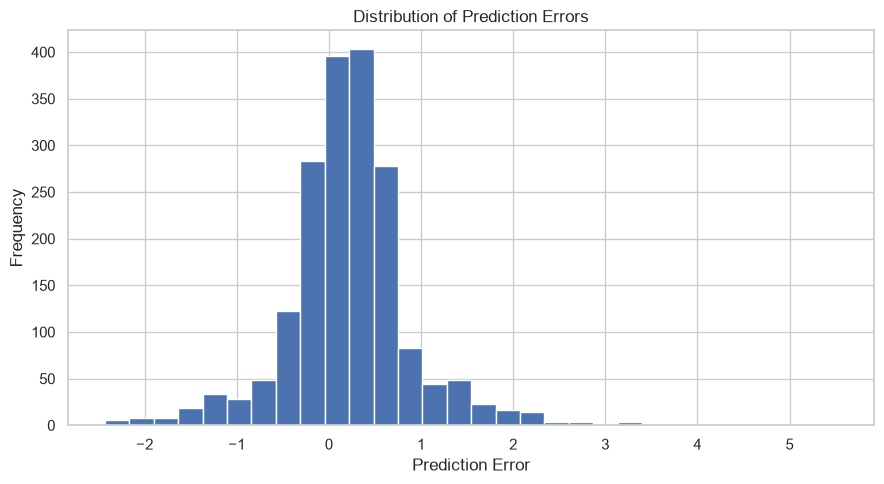

In [80]:
# Calculate prediction errors
errors = y_test.values - y_pred

plt.figure(figsize=(9, 5))

plt.hist(errors, bins=30)

plt.xlabel("Prediction Error")

plt.ylabel("Frequency")

plt.title("Distribution of Prediction Errors")

plt.tight_layout()

plt.show()